# Segmentação · Vitaliza · Grupo 2

**Pergunta desta etapa:** entre os pagantes ativos em 31/07/2026, em quantos grupos os assinantes se dividem, o que distingue cada grupo e o que a Vitaliza faria diferente com cada um?

Seguimos o roteiro das aulas 3 e 4: escolher e padronizar as variáveis, rodar o k-means de k = 2 a 8, escolher o k pelas quatro lentes (inércia, silhueta, estabilidade e leitura de negócio) e só **depois** olhar a saída de cada grupo. A saída não entra no agrupamento: o objetivo é descrever comportamentos, e o churn é o pano de fundo.

Este trabalho está no branch `cluster-v1` e entra na `main` por pull request, revisado por um colega que não escreveu o código.

In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, adjusted_rand_score

pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 40)
pd.set_option("display.float_format", lambda v: f"{v:,.2f}")

RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
BRUTOS, PROC, FIGS = RAIZ / "dados" / "brutos", RAIZ / "dados" / "processados", RAIZ / "saidas" / "segmentacao"
FIGS.mkdir(parents=True, exist_ok=True)

CORTE = pd.Timestamp("2026-08-01")          # pagantes ativos em 31/07/2026 (fim do dia)
INICIO_USO = CORTE - pd.Timedelta(weeks=12)  # 12 semanas até o corte: 09/05 a 31/07
FIM_SAIDA = CORTE + pd.Timedelta(days=60)    # saída em 60 dias: até 29/09/2026
SEMENTE = 42
CORES = ["#d6453d", "#2d5fa8", "#2f7d4f", "#c98a1b", "#6b4fa0", "#6b6b6b", "#1d9aa0", "#a0522d"]

## Passo 1 · A população

**O que decidimos.** Pagantes ativos em 31/07/2026, pela mesma regra validada na análise exploratória: tem evento pago até a data e nenhuma `assinatura_expirada` até ela.

O slide da aula fala em "perto de 11.700 linhas". Na aula de 05/11, esse número apareceu como o tamanho de um dos grupos (os que "correm pouco") numa base de cerca de 20 mil contas, não como a população. Ficamos com a nossa regra, que reproduz os números oficiais do enunciado.

In [2]:
eventos = pd.read_csv(PROC / "eventos_assinatura.csv", parse_dates=["data_hora_brt"])
assinaturas = pd.read_csv(PROC / "assinaturas.csv", parse_dates=["inicio"])
usuarios = pd.read_csv(PROC / "usuarios.csv", keep_default_na=False, na_values={"idade": [""]})

antes = eventos[eventos["data_hora_brt"] < CORTE]
pagou = set(antes.loc[antes["plano"].notna(), "user_id"])
expirou = set(antes.loc[antes["evento"] == "assinatura_expirada", "user_id"])
base = sorted(pagou - expirou)
print(f"pagantes ativos em 31/07/2026: {len(base):,}")

pagantes ativos em 31/07/2026: 14,032


Os treinos passam pelas mesmas correções da análise exploratória: fuso do Garmin e tipos em inglês.

In [3]:
ativ = pd.read_parquet(BRUTOS / "atividades.parquet")
ativ["inicio"] = pd.to_datetime(ativ["inicio"])
ativ["inicio_brt"] = ativ["inicio"].where(ativ["origem"] != "garmin", ativ["inicio"] - pd.Timedelta(hours=3))
ativ["tipo_pt"] = ativ["tipo"].replace({"run": "corrida", "walk": "caminhada", "ride": "pedal", "strength": "forca"})
ativ["ar_livre"] = ativ["tipo_pt"].isin({"corrida", "caminhada", "pedal"})
print("mesmas correções da EDA: Garmin −3h e tipos em inglês traduzidos")

mesmas correções da EDA: Garmin −3h e tipos em inglês traduzidos


## Passo 2 · Escolher as variáveis

**As quatro da aula**, medidas nas 12 semanas até 31/07: treinos por semana, dias desde o último treino, tempo de casa e % de treinos ao ar livre.

**As duas do grupo** (a aula permite até duas):
- **aberturas do app por mês:** na análise exploratória, separou quem saiu de quem ficou (Spearman −0,12), e não depende de relógio;
- **minutos por treino:** separa intensidade de frequência; quem treina pouco, mas longo, não é igual a quem treina pouco e curto.

**Ficam de fora do k-means:** plano e canal, que são categorias e não distâncias, entram depois para descrever os grupos; e a idade, que testamos à parte no passo 4.

**Ausências:** quem não treinou nas 12 semanas fica com 0 treino, 0% ao ar livre e 0 minuto por treino.

In [4]:
jan = ativ[(ativ["inicio_brt"] >= INICIO_USO) & (ativ["inicio_brt"] < CORTE)]
g = jan.groupby("user_id").agg(treinos=("atividade_id", "size"), minutos=("duracao_min", "sum"), ar_livre=("ar_livre", "sum"))

v = pd.DataFrame(index=pd.Index(base, name="user_id"))
v = v.join(g)
v["treinos_semana"] = v["treinos"].fillna(0) / 12
v["pct_ar_livre"] = (v["ar_livre"] / v["treinos"]).fillna(0)
v["minutos_por_treino"] = (v["minutos"] / v["treinos"]).fillna(0)
ultimo = ativ[ativ["inicio_brt"] < CORTE].groupby("user_id")["inicio_brt"].max()
v["dias_sem_treino"] = ((CORTE - ultimo).dt.days).reindex(v.index).fillna((CORTE - pd.Timestamp("2026-01-01")).days)
v["tempo_casa_dias"] = (pd.Timestamp("2026-07-31") - assinaturas.set_index("user_id")["inicio"]).dt.days.reindex(v.index)
uso = pd.read_csv(BRUTOS / "uso_mensal.csv")
v["sessoes_app_mes"] = (uso[uso["mes"].isin(["2026-05", "2026-06", "2026-07"])]
                        .groupby("user_id")["sessoes_app"].mean().reindex(v.index).fillna(0))
v = v.join(usuarios.set_index("user_id")[["idade"]])
v = v.drop(columns=["treinos", "minutos", "ar_livre"])

VARS_AULA = ["treinos_semana", "dias_sem_treino", "tempo_casa_dias", "pct_ar_livre"]
VARS_GRUPO = ["sessoes_app_mes", "minutos_por_treino"]
print(f"linhas: {len(v):,} | sem treino nas 12 semanas: {(v['treinos_semana'] == 0).sum():,} | sem idade: {v['idade'].isna().sum():,}")
v[VARS_AULA + VARS_GRUPO + ["idade"]].describe(percentiles=[.25, .5, .75]).T[["count", "mean", "25%", "50%", "75%", "max"]]

linhas: 14,032 | sem treino nas 12 semanas: 833 | sem idade: 849


,count,mean,25%,50%,75%,max
treinos_semana,"14,032.00",1.90,0.83,1.75,2.67,11.67
dias_sem_treino,"14,032.00",17.45,1.00,3.00,10.00,212.00
tempo_casa_dias,"14,032.00",418.66,130.00,274.00,537.00,"2,152.00"
pct_ar_livre,"14,032.00",0.52,0.14,0.69,0.83,1.00
sessoes_app_mes,"14,032.00",8.52,3.00,6.33,12.67,64.33
minutos_por_treino,"14,032.00",44.50,39.00,43.00,49.06,512.00
idade,"13,183.00",47.57,39.00,47.00,55.00,74.00


**Como padronizamos.** O k-means mede distância, e sem padronizar a variável de maior unidade (tempo de casa, em centenas de dias) decidiria sozinha os grupos. Seguimos o que a aula de 05/11 fez:
1. **log** nas variáveis assimétricas (todas menos % ao ar livre), para a cauda não dominar;
2. **corte nos percentis 1 e 99**, para os extremos não puxarem o centro;
3. **z-score** (média 0, desvio 1).

Depois disso, todas as variáveis têm a mesma escala:

In [5]:
LOG = ["treinos_semana", "dias_sem_treino", "tempo_casa_dias", "sessoes_app_mes", "minutos_por_treino"]

def preparar(df, cols):
    x = df[cols].copy()
    for c in cols:
        if c in LOG:
            x[c] = np.log1p(x[c])
        x[c] = x[c].clip(x[c].quantile(.01), x[c].quantile(.99))
    return pd.DataFrame(StandardScaler().fit_transform(x), index=df.index, columns=cols)

VARS = VARS_AULA + VARS_GRUPO
z = preparar(v, VARS)
z.describe().T[["mean", "std", "min", "max"]]

,mean,std,min,max
treinos_semana,0.00,1.00,-1.86,2.07
dias_sem_treino,0.00,1.00,-1.15,2.58
tempo_casa_dias,-0.00,1.00,-3.23,1.81
pct_ar_livre,0.00,1.00,-1.44,1.36
sessoes_app_mes,-0.00,1.00,-1.96,1.98
minutos_por_treino,0.00,1.00,-3.87,1.17


## Passo 3 · Rodar de k = 2 a 8 e ler as curvas

`n_init = 10` e `random_state = 42` fixos, para quem rodar de novo obter o mesmo resultado. A silhueta é calculada numa amostra de 6.000 assinantes, também com semente fixa.

In [6]:
res = []
for k in range(2, 9):
    km = KMeans(n_clusters=k, n_init=10, random_state=SEMENTE).fit(z)
    sil = silhouette_score(z, km.labels_, sample_size=6000, random_state=SEMENTE)
    res.append({"k": k, "inércia": km.inertia_, "silhueta": sil,
                "menor grupo (%)": pd.Series(km.labels_).value_counts(normalize=True).min() * 100})
curvas = pd.DataFrame(res).set_index("k")
curvas["queda da inércia (%)"] = -curvas["inércia"].pct_change() * 100
curvas

,inércia,silhueta,menor grupo (%),queda da inércia (%)
k,,,,
2,"58,606.63",0.55,5.98,NaN
3,"43,599.10",0.28,5.95,25.61
4,"36,231.44",0.27,5.95,16.90
5,"29,955.99",0.29,5.95,17.32
6,"26,883.75",0.28,5.95,10.26
7,"24,215.83",0.27,5.95,9.92
8,"22,645.90",0.26,5.95,6.48


**Estabilidade:** para cada k, sorteamos a base de novo, com reposição, dez vezes, agrupamos cada amostra e comparamos com o agrupamento original pelo índice de Rand ajustado (1 = idêntico).

In [7]:
def estabilidade(k, n=10):
    ref = KMeans(n_clusters=k, n_init=10, random_state=SEMENTE).fit(z)
    aris = []
    rng = np.random.default_rng(SEMENTE)
    for _ in range(n):
        idx = rng.choice(len(z), len(z), replace=True)
        km = KMeans(n_clusters=k, n_init=10, random_state=SEMENTE).fit(z.iloc[idx])
        aris.append(adjusted_rand_score(ref.labels_, km.predict(z)))
    return np.mean(aris), np.min(aris)

estab = pd.DataFrame([(k, *estabilidade(k)) for k in range(2, 9)], columns=["k", "Rand médio", "Rand mínimo"]).set_index("k")
curvas.join(estab)

,inércia,silhueta,menor grupo (%),queda da inércia (%),Rand médio,Rand mínimo
k,,,,,,
2,"58,606.63",0.55,5.98,NaN,1.00,1.00
3,"43,599.10",0.28,5.95,25.61,0.98,0.94
4,"36,231.44",0.27,5.95,16.90,0.98,0.97
5,"29,955.99",0.29,5.95,17.32,0.98,0.97
6,"26,883.75",0.28,5.95,10.26,0.98,0.96
7,"24,215.83",0.27,5.95,9.92,0.97,0.95
8,"22,645.90",0.26,5.95,6.48,0.82,0.62


**Como cada k divide a base.** Para a leitura de negócio, olhamos o tamanho de cada grupo e quanto ele perde, de k = 2 a 5:

In [8]:
# Como cada k divide a base: % da base e saída em 60 dias de quem podia sair, por grupo
janela = eventos[(eventos["data_hora_brt"] >= CORTE) & (eventos["data_hora_brt"] < FIM_SAIDA)]
saiu_ = v.index.isin(set(janela.loc[janela["evento"] == "assinatura_expirada", "user_id"]))
ult_ = antes[antes["plano"].notna()].sort_values("data_hora_brt").groupby("user_id").last()["plano"].reindex(v.index)
pa_ = antes[antes["evento"].isin(["assinatura_iniciada", "renovacao"]) & (antes["plano"] == "anual")]
prox_ = (pa_.groupby("user_id")["data_hora_brt"].max() + pd.DateOffset(years=1)).reindex(v.index)
podia_ = (ult_ == "mensal") | prox_.between(CORTE, FIM_SAIDA, inclusive="left")
linhas = []
for k in [2, 3, 4, 5]:
    lab = KMeans(n_clusters=k, n_init=10, random_state=SEMENTE).fit(z).labels_
    t = pd.DataFrame({"grupo": lab, "saiu": saiu_, "podia": podia_.values}, index=v.index).join(v[["treinos_semana", "tempo_casa_dias"]])
    for g, d in t.groupby("grupo"):
        linhas.append({"k": k, "grupo": g, "% da base": len(d) / len(t) * 100,
                       "treinos/semana (mediana)": d["treinos_semana"].median(),
                       "tempo de casa (mediana)": d["tempo_casa_dias"].median(),
                       "saída 60d, quem podia sair (%)": d.loc[d["podia"], "saiu"].mean() * 100})
tamanhos = pd.DataFrame(linhas).sort_values(["k", "% da base"], ascending=[True, False]).set_index(["k", "grupo"])
tamanhos

% da base  treinos/semana (mediana)  tempo de casa (mediana)  saída 60d, quem podia sair (%)
k grupo                                                                                              
2 0          94.02                      1.83                   260.00                           18.98
  1           5.98                      0.00                   506.00                           66.95
3 0          56.65                      2.50                   297.00                           11.54
  2          37.40                      0.83                   204.00                           32.58
  1           5.95                      0.00                   506.00                           66.95
4 3          37.15                      2.42                   281.00                           13.32
  0          30.42                      2.17                   269.00                           11.51
  1          26.48                      0.58                   225.00                           40.53
  2           5.95                      0.00                   506.00                           66.95
5 4          33.82                      2.50                   303.50                           12.97
  2          28.00                      2.25                   290.00                           11.04
  1          20.37                      0.50                   315.00                           51.78
  0          11.86                      0.92                    28.00                           18.11
  3           5.95                      0.00                   506.00                           66.95

**Lendo as quatro lentes:**

- **Silhueta.** O k = 2 tem a maior (0,55), mas só separa os 6% que não treinaram nada do resto, o que não ajuda a decidir. De k = 3 a 7, a silhueta fica entre 0,27 e 0,29 (estrutura fraca, como na aula), e o **k = 5 tem a maior dessa faixa (0,29)**.
- **Inércia.** A queda é de 26% de 2 para 3, 17% de 3 para 4 e 17% de 4 para 5; **de 5 para 6 cai para 10%**. O cotovelo fica em k = 5.
- **Estabilidade.** O Rand fica em 0,97–0,98 até k = 7 e despenca em k = 8 (mínimo de 0,62). O k = 5 é estável.
- **Negócio.** Começamos testando k = 3, como na aula, e depois k = 4 e 5. O k = 3 junta todos os ativos num grupo só; o k = 4 separa os ativos ao ar livre dos ativos em ambiente fechado; o **k = 5 separa ainda os novatos**, que pedem uma ação própria de boas-vindas, e concentra nos esporádicos os assinantes de casa que estão sumindo.

**Decisão: k = 5.** É o ponto em que as quatro lentes concordam.

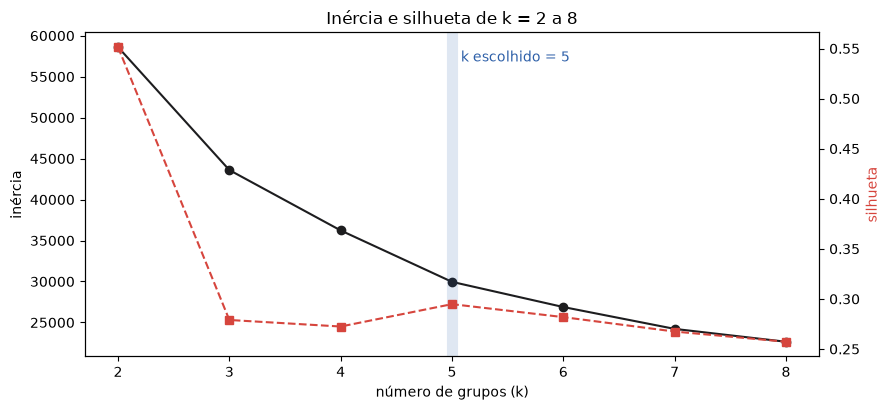

In [9]:
K = 5
fig, ax1 = plt.subplots(figsize=(9, 4.2))
ax1.plot(curvas.index, curvas["inércia"], "o-", color="#1d1d1f", label="inércia")
ax1.set_xlabel("número de grupos (k)"); ax1.set_ylabel("inércia")
ax2 = ax1.twinx(); ax2.plot(curvas.index, curvas["silhueta"], "s--", color="#d6453d", label="silhueta")
ax2.set_ylabel("silhueta", color="#d6453d")
ax1.axvline(K, color="#2d5fa8", lw=8, alpha=.15); ax1.text(K + .08, curvas["inércia"].max() * .97, f"k escolhido = {K}", color="#2d5fa8")
ax1.set_title("Inércia e silhueta de k = 2 a 8")
fig.tight_layout(); fig.savefig(FIGS / "01_inercia_silhueta.png", dpi=130, bbox_inches="tight"); plt.show()

## Passo 4 · Rodar o k escolhido e descrever cada grupo

**Saída em 60 dias:** `assinatura_expirada` entre 01/08 e 29/09/2026. Como vimos na análise exploratória, o anual só sai na renovação; por isso mostramos a taxa da base toda e a de **quem podia sair** (mensal, ou anual com renovação nessa janela).

In [10]:
def saida60(out):
    """Marca quem saiu em 60 dias após 31/07 e quem podia sair (mensal, ou anual com renovação na janela)."""
    janela = eventos[(eventos["data_hora_brt"] >= CORTE) & (eventos["data_hora_brt"] < FIM_SAIDA)]
    saiu = set(janela.loc[janela["evento"] == "assinatura_expirada", "user_id"])
    out = out.copy(); out["saiu_60d"] = out.index.isin(saiu).astype(int)
    ult = antes[antes["plano"].notna()].sort_values("data_hora_brt").groupby("user_id").last()
    out["plano"] = ult["plano"].reindex(out.index)
    pag_anual = antes[antes["evento"].isin(["assinatura_iniciada", "renovacao"]) & (antes["plano"] == "anual")]
    prox = pag_anual.groupby("user_id")["data_hora_brt"].max() + pd.DateOffset(years=1)
    out["podia_sair"] = (out["plano"] == "mensal") | prox.reindex(out.index).between(CORTE, FIM_SAIDA, inclusive="left")
    return out
print("janela de saída: 01/08 a", (FIM_SAIDA - pd.Timedelta(days=1)).strftime("%d/%m/%Y"))

janela de saída: 01/08 a 29/09/2026


**Conferência do auditor:** rodamos com outra semente (7). O Rand de 1,000 mostra que o resultado não depende do sorteio inicial.

A tabela abaixo mostra como os grupos do k = 4 se repartem no k = 5: os ativos continuam praticamente iguais, e o grupo de baixa frequência se divide em **novatos** e **esporádicos**.

In [11]:
km = KMeans(n_clusters=K, n_init=10, random_state=SEMENTE).fit(z)
seg = saida60(v.join(pd.Series(km.labels_, index=z.index, name="grupo")))

outra = KMeans(n_clusters=K, n_init=10, random_state=7).fit(z)
print(f"Conferência do auditor: outra semente (7) contra a nossa (42), Rand ajustado = {adjusted_rand_score(km.labels_, outra.labels_):.3f}")

k4 = KMeans(n_clusters=4, n_init=10, random_state=SEMENTE).fit(z).labels_
pd.crosstab(pd.Series(k4, name="grupo com k=4"), pd.Series(km.labels_, name="grupo com k=5"))

Conferência do auditor: outra semente (7) contra a nossa (42), Rand ajustado = 1.000


grupo com k=5,0,1,2,3,4
grupo com k=4,,,,,
0,304,54,3911,0,0
1,896,2730,18,0,71
2,0,0,0,835,0
3,464,74,0,0,4675


**Um nome por grupo**, dado pelo comportamento que o distingue, sem personagem inventado. O nome é uma hipótese a testar, e a regra que atribui cada nome está no código acima (menor frequência = Parados; menor tempo de casa entre os demais = Novatos; e assim por diante).

Perfil de cada segmento, em medianas na unidade original:

In [12]:
NOMES = {}
med = seg.groupby("grupo")[["treinos_semana", "pct_ar_livre", "tempo_casa_dias"]].median()
parado = med["treinos_semana"].idxmin(); NOMES[parado] = "Parados"
resto = med.drop(parado)
novato = resto["tempo_casa_dias"].idxmin(); NOMES[novato] = "Novatos"
resto = resto.drop(novato)
espor = resto["treinos_semana"].idxmin(); NOMES[espor] = "Esporádicos"
ativos = resto.drop(espor)
NOMES[ativos["pct_ar_livre"].idxmax()] = "Ativos ao ar livre"
NOMES[ativos["pct_ar_livre"].idxmin()] = "Ativos em ambiente fechado"
ORDEM = ["Ativos ao ar livre", "Ativos em ambiente fechado", "Novatos", "Esporádicos", "Parados"]
seg["segmento"] = pd.Categorical(seg["grupo"].map(NOMES), ORDEM)

perfis = seg.groupby("segmento", observed=True).agg(
    assinantes=("grupo", "size"),
    treinos_semana=("treinos_semana", "median"), dias_sem_treino=("dias_sem_treino", "median"),
    pct_ar_livre=("pct_ar_livre", "median"), minutos_por_treino=("minutos_por_treino", "median"),
    sessoes_app_mes=("sessoes_app_mes", "median"), tempo_casa_dias=("tempo_casa_dias", "median"),
    idade=("idade", "median"), pct_mensal=("plano", lambda s: (s == "mensal").mean() * 100),
    saida_60d=("saiu_60d", "mean"), saidas=("saiu_60d", "sum"))
perfis["% da base"] = perfis["assinantes"] / perfis["assinantes"].sum() * 100
perfis["% das saídas"] = perfis["saidas"] / perfis["saidas"].sum() * 100
perfis["saida_60d"] *= 100
perfis["saída 60d, quem podia sair"] = seg[seg["podia_sair"]].groupby("segmento", observed=True)["saiu_60d"].mean() * 100
perfis["pct_ar_livre"] *= 100
print(f"saída média em 60 dias: {seg['saiu_60d'].mean():.1%} | entre quem podia sair: {seg.loc[seg['podia_sair'], 'saiu_60d'].mean():.1%}")
perfis.T

saída média em 60 dias: 10.5% | entre quem podia sair: 20.6%


segmento,Ativos ao ar livre,Ativos em ambiente fechado,Novatos,Esporádicos,Parados
assinantes,"4,746.00","3,929.00","1,664.00","2,858.00",835.00
treinos_semana,2.50,2.25,0.92,0.50,0.00
dias_sem_treino,1.00,2.00,2.00,20.00,167.00
pct_ar_livre,80.56,14.29,72.73,76.92,0.00
minutos_por_treino,46.99,41.61,43.77,44.76,0.00
sessoes_app_mes,11.00,9.50,5.50,2.33,1.33
tempo_casa_dias,303.50,290.00,28.00,315.00,506.00
idade,46.00,47.00,46.00,47.00,46.00
pct_mensal,47.01,50.32,61.72,17.63,0.84
saida_60d,7.04,6.26,11.36,18.82,19.40


**O que cada segmento é, em uma frase de negócio:**

| Segmento | Quem é | O que a Vitaliza faria diferente |
| :-- | :-- | :-- |
| **Ativos ao ar livre** (34%) | Treinam 2,5 vezes por semana, 81% correndo, caminhando ou pedalando | Manter o engajamento com desafios e metas de corrida; baixo risco (13% entre quem podia sair) |
| **Ativos em ambiente fechado** (28%) | Mesma frequência, mas 86% em força, funcional, HIIT e yoga | Manter com conteúdo novo em vídeo; o segmento de menor risco (11%) |
| **Novatos** (12%) | Um mês de casa, menos de um treino por semana, 62% no mensal | Boas-vindas e primeiro plano de treino; risco moderado (18%) |
| **Esporádicos** (20%) | Quase um ano de casa, um treino a cada duas semanas, 20 dias sem treinar, 82% no anual | **Prioridade:** 52% de saída entre quem podia sair e 37% de todas as saídas; agir antes da renovação, a partir de 8 dias sem treino |
| **Parados** (6%) | Nenhum treino em 12 semanas, quase todos no anual | Maior risco (67% entre quem podia sair), mas um contato pode lembrá-los de que pagam por algo que não usam; testar com cuidado |

O gráfico que responde à pergunta "qual segmento mais perde assinantes?":

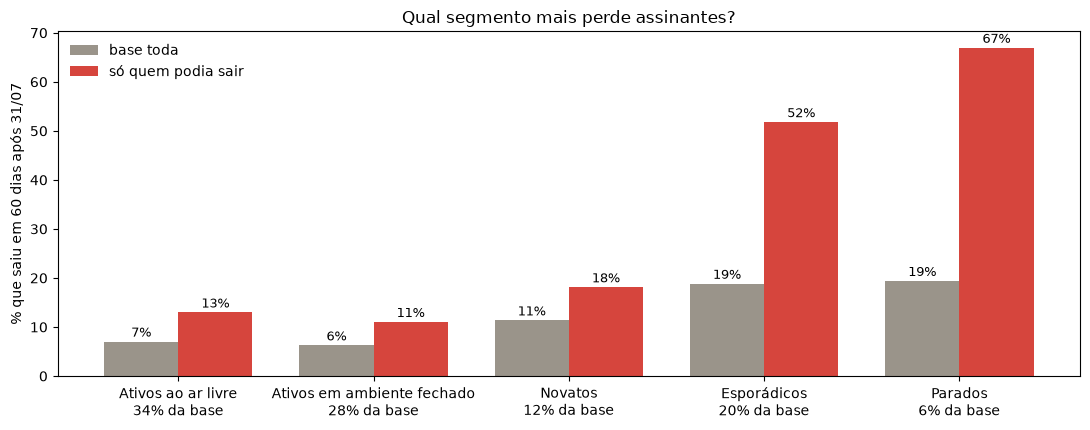

In [13]:
fig, ax = plt.subplots(figsize=(11, 4.4))
x = np.arange(len(perfis)); w = .38
ax.bar(x - w / 2, perfis["saida_60d"], w, color="#9a948a", label="base toda")
ax.bar(x + w / 2, perfis["saída 60d, quem podia sair"], w, color="#d6453d", label="só quem podia sair")
for i, (a, b) in enumerate(zip(perfis["saida_60d"], perfis["saída 60d, quem podia sair"])):
    ax.text(i - w / 2, a + 1, f"{a:.0f}%", ha="center", fontsize=9); ax.text(i + w / 2, b + 1, f"{b:.0f}%", ha="center", fontsize=9)
ax.set_xticks(x, [f"{n}" + chr(10) + f"{p:.0f}% da base" for n, p in zip(perfis.index, perfis["% da base"])])
ax.set_ylabel("% que saiu em 60 dias após 31/07"); ax.legend(frameon=False)
ax.set_title("Qual segmento mais perde assinantes?")
fig.tight_layout(); fig.savefig(FIGS / "02_saida_por_segmento.png", dpi=130, bbox_inches="tight"); plt.show()

Os **esporádicos** não são o grupo de maior taxa (os parados são), mas são o grupo que **mais perde em número**: 538 das 1.469 saídas. Somados aos parados, respondem por quase metade das saídas com um quarto da base.

O gráfico pedido na aula de 05/11, com a idade no tamanho do ponto:

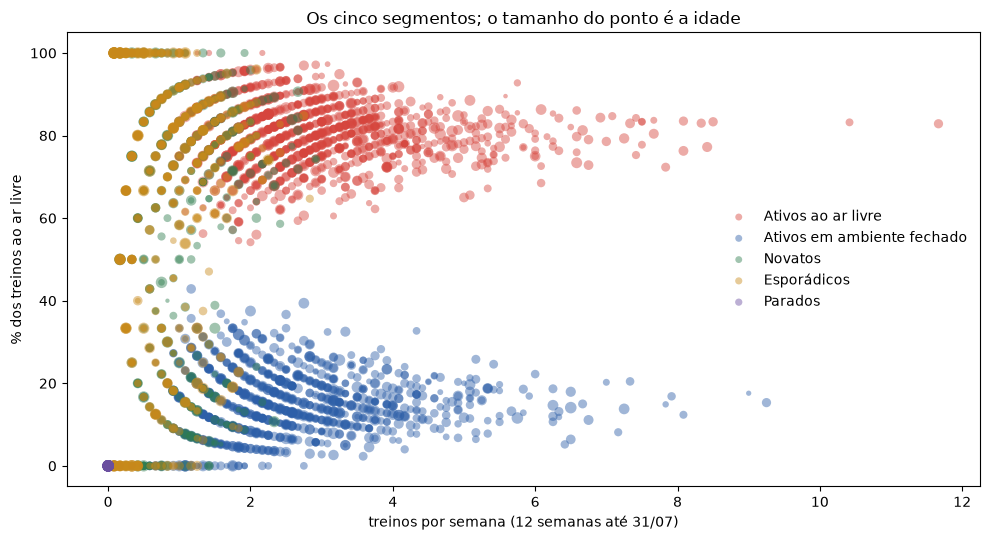

In [14]:
amostra = seg.sample(4000, random_state=SEMENTE)
fig, ax = plt.subplots(figsize=(10, 5.5))
for i, nome in enumerate(ORDEM):
    a = amostra[amostra["segmento"] == nome]
    tam = (a["idade"].fillna(a["idade"].median()) - 15) * 1.2
    ax.scatter(a["treinos_semana"], a["pct_ar_livre"] * 100, s=tam, alpha=.45, color=CORES[i], label=nome, edgecolors="none")
ax.set_xlabel("treinos por semana (12 semanas até 31/07)"); ax.set_ylabel("% dos treinos ao ar livre")
ax.set_title("Os cinco segmentos; o tamanho do ponto é a idade")
leg = ax.legend(frameon=False, loc="center right", markerscale=.8)
fig.tight_layout(); fig.savefig(FIGS / "03_dispersao_idade.png", dpi=130, bbox_inches="tight"); plt.show()

Pontos grandes e pequenos aparecem misturados em todos os segmentos: **a idade não separa os grupos**, o mesmo resultado da aula. Para confirmar, rodamos o k-means com a idade como sétima variável:

In [15]:
z_idade = preparar(v.assign(idade=v["idade"].fillna(v["idade"].median())), VARS + ["idade"])
lab_i = KMeans(n_clusters=K, n_init=10, random_state=SEMENTE).fit(z_idade).labels_
print(f"k={K}: silhueta sem idade {silhouette_score(z, km.labels_, sample_size=6000, random_state=SEMENTE):.3f} | "
      f"com idade {silhouette_score(z_idade, lab_i, sample_size=6000, random_state=SEMENTE):.3f} | "
      f"Rand entre as duas segmentações {adjusted_rand_score(km.labels_, lab_i):.3f}")
seg.groupby("segmento", observed=True)["idade"].describe()[["25%", "50%", "75%"]]

k=5: silhueta sem idade 0.295 | com idade 0.234 | Rand entre as duas segmentações 0.985


,25%,50%,75%
segmento,,,
Ativos ao ar livre,39.00,46.00,54.00
Ativos em ambiente fechado,40.00,47.00,55.00
Novatos,39.00,46.00,54.00
Esporádicos,40.00,47.00,55.00
Parados,39.00,46.00,55.00


Incluir a idade **piora** a silhueta (de 0,295 para 0,234) e quase não muda os grupos (Rand de 0,985 entre as duas versões). A mediana de idade é de 46–47 anos em todos os segmentos. **Decisão:** a idade fica fora do agrupamento e entra só como descrição. É coerente com a trilha de negócios, em que idade e gênero descrevem, mas não são gatilho de ação.

## Passo 5 · Salvar e conferir

Gravamos as variáveis, a versão padronizada e o segmento de cada assinante em `dados/processados/`, e o resumo dos perfis em `saidas/perfis.md`.

In [16]:
v.reset_index().to_csv(PROC / "variaveis_31jul.csv", index=False)
z.reset_index().to_csv(PROC / "variaveis_z_31jul.csv", index=False)
seg[["grupo", "segmento", "saiu_60d", "podia_sair", "plano"]].reset_index().to_csv(PROC / "segmentos_31jul.csv", index=False)

br = lambda x, d=1: f"{x:,.{d}f}".replace(",", "X").replace(".", ",").replace("X", ".")
linhas = ["# Perfis dos segmentos (k = 5, pagantes ativos em 31/07/2026)", "",
          "Gerado por `notebooks/03_segmentacao.ipynb`. Medianas na unidade original; saída = `assinatura_expirada` em 60 dias após 31/07.", "",
          "| Segmento | Assinantes | % da base | Treinos/semana | Dias sem treino | % ao ar livre | Saída 60d | Saída 60d (quem podia sair) | % das saídas |",
          "| :-- | --: | --: | --: | --: | --: | --: | --: | --: |"]
for n, r in perfis.iterrows():
    linhas.append(f"| {n} | {br(r['assinantes'], 0)} | {br(r['% da base'])}% | {br(r['treinos_semana'], 2)} | {br(r['dias_sem_treino'], 0)} | "
                  f"{br(r['pct_ar_livre'], 0)}% | {br(r['saida_60d'])}% | {br(r['saída 60d, quem podia sair'])}% | {br(r['% das saídas'])}% |")
(RAIZ / "saidas" / "perfis.md").write_text(chr(10).join(linhas) + chr(10), encoding="utf-8")
print("gravados: variaveis_31jul.csv, variaveis_z_31jul.csv, segmentos_31jul.csv e saidas/perfis.md")

gravados: variaveis_31jul.csv, variaveis_z_31jul.csv, segmentos_31jul.csv e saidas/perfis.md


Três assinantes sorteados (semente 42), abertos à mão:

In [17]:
for u in seg.sample(3, random_state=SEMENTE).index:
    r = seg.loc[u]
    ult = ativ.loc[(ativ["user_id"] == u) & (ativ["inicio_brt"] < CORTE), "inicio_brt"].max()
    n12 = ((ativ["user_id"] == u) & (ativ["inicio_brt"] >= INICIO_USO) & (ativ["inicio_brt"] < CORTE)).sum()
    print(f"{u} | {r['segmento']:<27} | treinos em 12 semanas: {n12:>3} (= {r['treinos_semana']:.2f}/semana) | último treino: {ult} | plano: {r['plano']} | saiu em 60d: {r['saiu_60d']}")

u_81bd1ff6 | Ativos ao ar livre          | treinos em 12 semanas:  57 (= 4.75/semana) | último treino: 2026-07-29 18:56:00 | plano: anual | saiu em 60d: 0
u_b03c28b6 | Ativos em ambiente fechado  | treinos em 12 semanas:  24 (= 2.00/semana) | último treino: 2026-07-31 12:23:00 | plano: anual | saiu em 60d: 0
u_381a15b2 | Ativos em ambiente fechado  | treinos em 12 semanas:  37 (= 3.08/semana) | último treino: 2026-07-20 20:49:00 | plano: anual | saiu em 60d: 1


Os três conferem com o segmento: o de 4,75 treinos por semana, quase só ao ar livre, está em "Ativos ao ar livre"; os dois com treinos frequentes e pouco ar livre estão em "Ativos em ambiente fechado". O terceiro saiu mesmo sendo ativo. Treinar muito não garante a renovação, e o segmento descreve o comportamento, não prevê a saída de uma pessoa.

## O que concluímos

1. **A base se divide em cinco grupos de comportamento**, estáveis (Rand de 1,000 com outra semente) e com o k defendido pelas quatro lentes.
2. **Os esporádicos são o alvo principal:** 20% da base, 37% das saídas e 52% de saída entre quem podia sair. São assinantes antigos, quase todos do anual, que foram parando de treinar. O limiar de 8 dias sem treino, achado na análise exploratória, é o gatilho natural para agir antes da renovação.
3. **O que o agrupamento não diz:** ele descreve grupos, não prevê quem vai sair. Um ativo pode sair, e um parado pode renovar. Prever a saída de cada pessoa é o modelo das aulas 6 a 8.

**Limites:** a silhueta de 0,29 indica estrutura fraca, com grupos que se tocam nas bordas; as variáveis cobrem 12 semanas; e o plano não entrou no agrupamento.

As decisões desta etapa estão no `decisoes.md`.